# Práctica 2 EDA — Rol C: Análisis exploratorio (EDA)

**Parte 1 de la guía del Rol C.** Este notebook explica los dos datasets con gráficas; cada gráfica responde
**una pregunta concreta** y lleva debajo una **interpretación de 1–3 líneas**.

| Dataset | Archivo | Objetivo |
|---|---|---|
| Titanic | `data/raw/titanic.csv` | `Survived` |
| Credit Card Fraud | `data/raw/creditcard.csv` | `Class` |

**Mínimo visual cubierto por dataset:** 2 histogramas, 2 boxplots, 2 gráficas de barras de categóricas,
1 matriz de correlación, 1 distribución de clases y 1 atributo vs. objetivo. Además: tabla de asimetría y
una gráfica de relación no lineal por dataset.

**Cómo se hizo (reglas del equipo):**
- Se explora el **dato crudo** completo (`cargar_datos()` de `src/utils.py`, Rol A). Aquí **no se ajusta ninguna
  transformación** (ni imputar, winsorizar, escalar ni balancear), así que no hay fuga de información hacia test.
- Las gráficas se guardan en `figuras/` con el prefijo `c_` para reusarlas en la presentación y el informe.
- Las cifras de calidad (nulos, outliers, duplicados) vienen del profiling del Rol B (`01_profiling.ipynb`,
  `docs/ficha_tecnica.md`) y se citan como "cifras de B".
- **Fraud no tiene variables categóricas** (todas son numéricas). Para cubrir las gráficas de barras se
  construyeron dos categóricas derivadas **solo para el EDA** (bloque de 6 h desde el inicio y rango de monto);
  no se usan en el modelo.

### Uso de IA generativa
Se usó Claude para generar el borrador de este notebook (estructura, código de las gráficas e interpretaciones
iniciales). Las cifras de Titanic salen de ejecutar el código sobre `titanic.csv`; las de Fraud se contrastan con las
cifras de B. El integrante del Rol C revisa, ejecuta y puede explicar y modificar el código.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import seaborn as sns

sys.path.append("..")
from src.utils import cargar_datos

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras"; FIG.mkdir(exist_ok=True)

# Paleta común del equipo: clase 0 en gris, clase 1 en rojo (igual que el notebook del Rol E)
GRIS, ROJO, AZUL, NARANJA = "#7a8794", "#d1495b", "#2f6690", "#e9a03b"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid.axis": "y"})
CAJA = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)   # fondo para las etiquetas
pd.set_option("display.float_format", "{:.3f}".format)


def guardar(fig, nombre):
    """Guarda la figura en figuras/c_<nombre>.png y la muestra."""
    fig.tight_layout()
    fig.savefig(FIG / f"c_{nombre}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def etiquetar_barras(ax, total=None):
    """Escribe el conteo (y el %) encima de cada barra."""
    for b in ax.patches:
        h = b.get_height()
        if not np.isfinite(h) or h <= 0:
            continue
        txt = f"{int(h):,}" + (f"\n({100 * h / total:.1f} %)" if total else "")
        ax.annotate(txt, (b.get_x() + b.get_width() / 2, h), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, bbox=CAJA)


def barras_conteo(serie, titulo, xlabel, nombre, orden=None, log=False, figsize=(5.5, 4)):
    """Barras de una categórica; los nulos se muestran como 'Sin dato' (en gris)."""
    s = serie.astype("object").where(serie.notna(), "Sin dato")
    conteo = s.value_counts()
    if orden is not None:
        conteo = conteo.reindex([o for o in orden if o in conteo.index])
    colores = [GRIS if str(k) == "Sin dato" else AZUL for k in conteo.index]
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(conteo.index.astype(str), conteo.values, color=colores)
    etiquetar_barras(ax, total=conteo.sum())
    ax.set_title(titulo); ax.set_xlabel(xlabel)
    ax.set_ylabel("conteo" + (" (escala log)" if log else ""))
    if log:
        ax.set_yscale("log")
    ax.margins(y=0.25)
    guardar(fig, nombre)
    return conteo


def tasa_por_grupo(grupo, objetivo, titulo, xlabel, ylabel, nombre, global_pct=None, color=ROJO,
                   figsize=(6, 4), dec=1):
    """Barras con la tasa (%) de la clase 1 por grupo, mostrando el tamaño n de cada grupo."""
    g = objetivo.groupby(grupo, observed=True).agg(["mean", "size"])
    tasa = 100 * g["mean"]
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(g.index.astype(str), tasa.values, color=color)
    for x, (t, n) in enumerate(zip(tasa.values, g["size"].values)):
        ax.annotate(f"{t:.{dec}f} %\n(n={n:,})", (x, t), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, bbox=CAJA)
    if global_pct is not None:
        ax.axhline(global_pct, ls="--", color="black", lw=1)
        titulo += f"\n(línea punteada = tasa global {global_pct:.{dec}f} %)"
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.margins(y=0.25)
    guardar(fig, nombre)
    return pd.DataFrame({"tasa_%": tasa, "n": g["size"]})


def tabla_asimetria(df, columnas, n=10):
    """Asimetría y curtosis, ordenadas por |asimetría|."""
    t = pd.DataFrame({"asimetría": df[columnas].skew(), "curtosis": df[columnas].kurt()})
    return t.reindex(t["asimetría"].abs().sort_values(ascending=False).index).head(n)

---
# 1. Titanic

In [2]:
titanic = cargar_datos("titanic")
# columnas auxiliares solo para etiquetar las gráficas en español
titanic["Estado"] = titanic["Survived"].map({0: "No sobrevivió", 1: "Sobrevivió"})
titanic["Sexo"] = titanic["Sex"].map({"male": "Hombres", "female": "Mujeres"})
PAL_T = {"No sobrevivió": GRIS, "Sobrevivió": ROJO}
print(f"Titanic: {titanic.shape[0]} filas × {titanic.shape[1]} columnas (con las columnas auxiliares 'Estado' y 'Sexo')")
display(titanic.head())

Titanic: 891 filas × 14 columnas (con las columnas auxiliares 'Estado' y 'Sexo')


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Estado,Sexo
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S,No sobrevivió,Hombres
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C,Sobrevivió,Mujeres
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S,Sobrevivió,Mujeres
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S,Sobrevivió,Mujeres
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S,No sobrevivió,Hombres


### 1.1 Histogramas

**Pregunta 1.** ¿Cómo se distribuye la edad de los pasajeros y qué tan simétrica es?

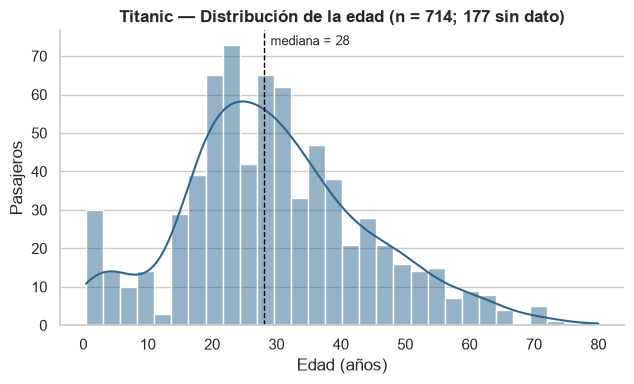

asimetría = 0.39 · media = 29.7 · mediana = 28 · Q1–Q3 = 20.1–38.0


In [3]:
edad = titanic["Age"].dropna()
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.histplot(edad, bins=30, kde=True, color=AZUL, ax=ax)
ax.axvline(edad.median(), ls="--", color="black", lw=1)
ax.annotate(f"mediana = {edad.median():.0f}", (edad.median(), ax.get_ylim()[1] * 0.95),
            xytext=(5, 0), textcoords="offset points", fontsize=9)
ax.set_title(f"Titanic — Distribución de la edad (n = {len(edad)}; {titanic['Age'].isna().sum()} sin dato)")
ax.set_xlabel("Edad (años)"); ax.set_ylabel("Pasajeros")
guardar(fig, "titanic_hist_edad")
print(f"asimetría = {edad.skew():.2f} · media = {edad.mean():.1f} · mediana = {edad.median():.0f} · "
      f"Q1–Q3 = {edad.quantile(.25):.1f}–{edad.quantile(.75):.1f}")

**Interpretación.** La edad es casi simétrica (asimetría 0.39): mediana de 28 años, media de 29.7 y la mitad central
de los pasajeros entre 20 y 38 años. Se ve un pico pequeño de niños menores de 5 años. Solo se grafican 714 de 891
pasajeros: faltan 177 edades (19.9 %), un hueco que luego tendrá que imputar el Rol D.

**Pregunta 2.** ¿Cómo se distribuye la tarifa pagada y por qué importa su cola derecha?

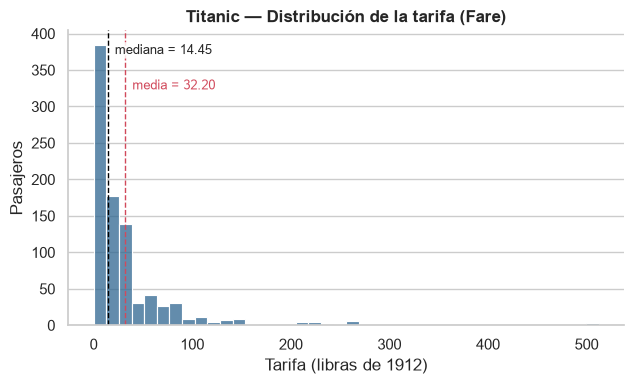

asimetría = 4.79 · p99 = 249.01 · máximo = 512.33 · ≤ 30: 73.7 % de los pasajeros


In [4]:
tarifa = titanic["Fare"]
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.histplot(tarifa, bins=40, color=AZUL, ax=ax)
ax.axvline(tarifa.median(), ls="--", color="black", lw=1)
ax.axvline(tarifa.mean(), ls="--", color=ROJO, lw=1)
ax.annotate(f"mediana = {tarifa.median():.2f}", (tarifa.median(), ax.get_ylim()[1] * 0.92),
            xytext=(5, 0), textcoords="offset points", fontsize=9, bbox=CAJA)
ax.annotate(f"media = {tarifa.mean():.2f}", (tarifa.mean(), ax.get_ylim()[1] * 0.80),
            xytext=(5, 0), textcoords="offset points", fontsize=9, color=ROJO, bbox=CAJA)
ax.set_title("Titanic — Distribución de la tarifa (Fare)")
ax.set_xlabel("Tarifa (libras de 1912)"); ax.set_ylabel("Pasajeros")
guardar(fig, "titanic_hist_tarifa")
print(f"asimetría = {tarifa.skew():.2f} · p99 = {tarifa.quantile(.99):.2f} · máximo = {tarifa.max():.2f} · "
      f"≤ 30: {100 * (tarifa <= 30).mean():.1f} % de los pasajeros")

**Interpretación.** Muy asimétrica a la derecha (asimetría 4.79): la mediana es 14.45 pero la media sube a 32.20 por
unos pocos boletos caros (p99 = 249.01; máximo 512.33). El 73.7 % pagó 30 o menos. Es la candidata natural a
winsorización (Rol D).

### 1.2 Boxplots

**Pregunta 1.** ¿Cambia la tarifa según la clase del boleto?

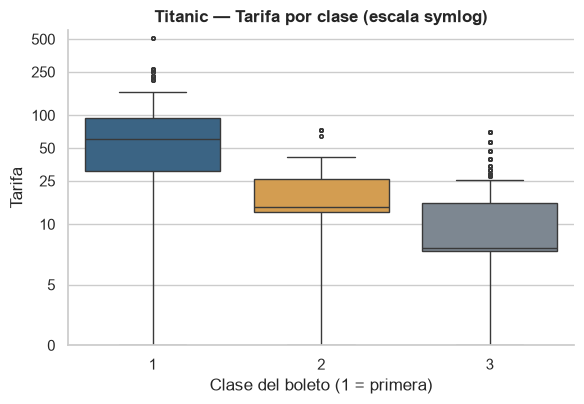

,count,50%,mean,max
Pclass,,,,
1,216.000,60.287,84.155,512.329
2,184.000,14.250,20.662,73.500
3,491.000,8.050,13.676,69.550


In [5]:
fig, ax = plt.subplots(figsize=(6, 4.2))
sns.boxplot(data=titanic, x="Pclass", y="Fare", hue="Pclass", palette=[AZUL, NARANJA, GRIS],
            legend=False, fliersize=2.5, ax=ax)
ax.set_yscale("symlog", linthresh=10)          # escala log que admite el 0 (hay 15 tarifas en 0)
ax.set_ylim(0, 600); ax.set_yticks([0, 5, 10, 25, 50, 100, 250, 500]); ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_title("Titanic — Tarifa por clase (escala symlog)")
ax.set_xlabel("Clase del boleto (1 = primera)"); ax.set_ylabel("Tarifa")
guardar(fig, "titanic_box_tarifa_clase")
display(titanic.groupby("Pclass")["Fare"].describe()[["count", "50%", "mean", "max"]])

**Interpretación.** Sí, y mucho: la mediana es 60.29 en 1.ª clase, 14.25 en 2.ª y 8.05 en 3.ª. La 1.ª clase concentra la
dispersión y los valores extremos (hasta 512.33), pero también hay outliers dentro de 2.ª y 3.ª clase. Clase y tarifa
llevan casi la misma información (Pclass–Fare: −0.55).

**Pregunta 2.** ¿Tenían edades distintas quienes sobrevivieron y quienes no?

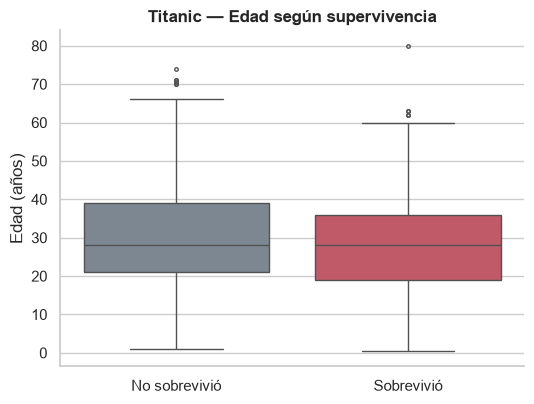

,count,25%,50%,75%,mean
Estado,,,,,
No sobrevivió,424.000,21.000,28.000,39.000,30.626
Sobrevivió,290.000,19.000,28.000,36.000,28.344


In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.boxplot(data=titanic, x="Estado", y="Age", hue="Estado", palette=PAL_T, order=list(PAL_T),
            legend=False, fliersize=2.5, ax=ax)
ax.set_title("Titanic — Edad según supervivencia")
ax.set_xlabel(""); ax.set_ylabel("Edad (años)")
guardar(fig, "titanic_box_edad_supervivencia")
display(titanic.groupby("Estado")["Age"].describe()[["count", "25%", "50%", "75%", "mean"]])

**Interpretación.** Las dos cajas se traslapan casi por completo: la mediana es 28 años en ambos grupos (media 28.3 de
quienes sobrevivieron vs 30.6 de quienes no). Por sí sola, la edad separa poco las clases (correlación −0.08); su efecto
aparece solo en los niños pequeños (ver sección 1.7).

### 1.3 Barras de variables categóricas

**Pregunta 1.** ¿Cómo se reparten los pasajeros por sexo?

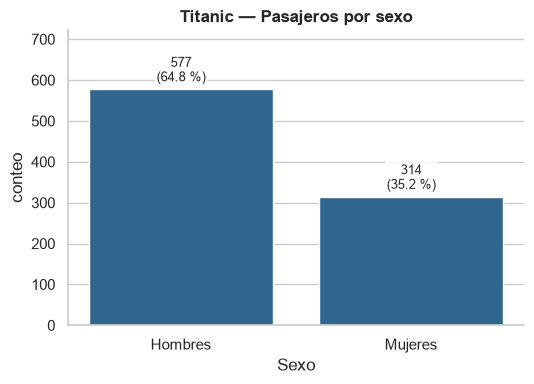

Sexo
Hombres    577
Mujeres    314
Name: count, dtype: int64

In [7]:
conteo_sex = barras_conteo(titanic["Sexo"], "Titanic — Pasajeros por sexo", "Sexo", "titanic_barras_sexo",
                           orden=["Hombres", "Mujeres"])
display(conteo_sex)

**Interpretación.** Viajaban más hombres (577; 64.8 %) que mujeres (314; 35.2 %): una distribución moderadamente
desigual y sin valores faltantes. Es relevante porque el sexo resultará ser la variable que más separa las clases.

**Pregunta 2.** ¿Desde qué puerto embarcaron y cuántos datos faltan?

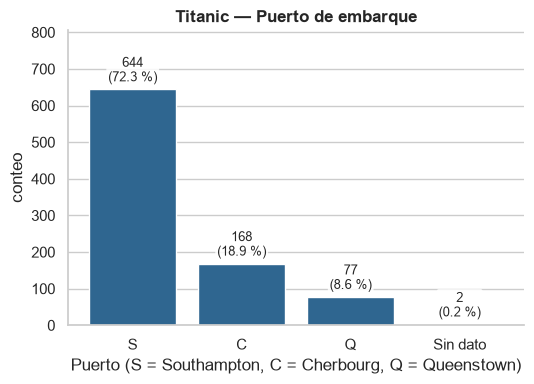

Embarked
S           644
C           168
Q            77
Sin dato      2
Name: count, dtype: int64

In [8]:
conteo_emb = barras_conteo(titanic["Embarked"], "Titanic — Puerto de embarque",
                           "Puerto (S = Southampton, C = Cherbourg, Q = Queenstown)", "titanic_barras_embarque",
                           orden=["S", "C", "Q", "Sin dato"])
display(conteo_emb)

**Interpretación.** Southampton domina con 644 pasajeros (72.4 %), seguido de Cherbourg (168; 18.9 %) y Queenstown
(77; 8.7 %). Solo 2 pasajeros no tienen puerto (0.2 %). Con una moda tan marcada, imputar con la moda ('S') es la
opción simple (Rol D).

### 1.4 Matriz de correlación

**Pregunta.** ¿Qué variables numéricas están relacionadas entre sí y con la supervivencia?

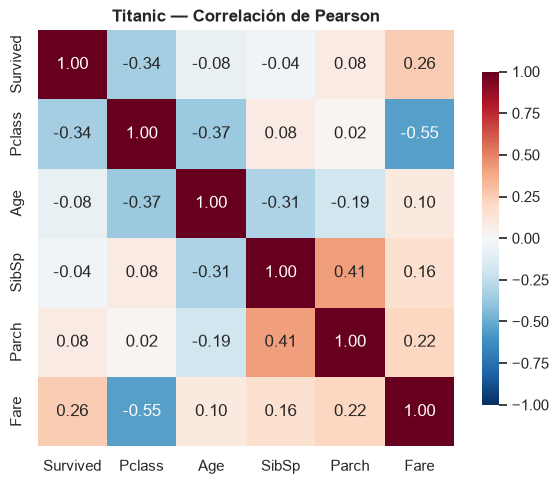

In [9]:
cols_t = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr_t = titanic[cols_t].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr_t, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Titanic — Correlación de Pearson")
guardar(fig, "titanic_correlacion")

**Interpretación.** Ningún par supera |r| = 0.8, así que no hay redundancia fuerte. Las relaciones más claras son
Pclass–Fare (−0.55) y Pclass–Age (−0.37), y con la supervivencia pesan Pclass (−0.34) y Fare (0.26). Age, SibSp y Parch
casi no se relacionan linealmente con Survived (|r| ≤ 0.08), lo que no descarta efectos no lineales (sección 1.7).

### 1.5 Distribución de clases

**Pregunta.** ¿Qué tan desbalanceada está la variable objetivo?

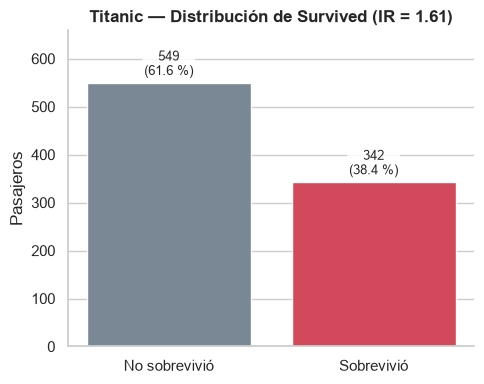

In [10]:
cl = titanic["Estado"].value_counts().reindex(list(PAL_T))
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(cl.index, cl.values, color=[PAL_T[k] for k in cl.index])
etiquetar_barras(ax, total=cl.sum())
ax.set_title(f"Titanic — Distribución de Survived (IR = {cl.max() / cl.min():.2f})")
ax.set_ylabel("Pasajeros"); ax.margins(y=0.2)
guardar(fig, "titanic_clases")

**Interpretación.** 549 pasajeros no sobrevivieron (61.6 %) y 342 sí (38.4 %): IR = 1.61, apenas por encima del umbral de
1.5, así que el desbalance es leve. Un modelo que siempre dijera "no sobrevive" tendría ~61.6 % de accuracy.

### 1.6 Atributo vs. objetivo

**Pregunta.** ¿La supervivencia depende del sexo?

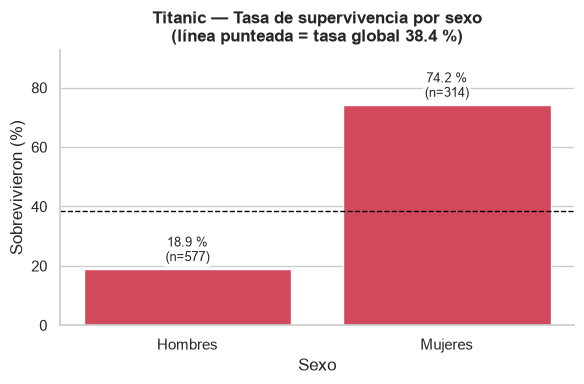

,tasa_%,n
Sexo,,
Hombres,18.891,577
Mujeres,74.204,314


In [11]:
t_sex = tasa_por_grupo(titanic["Sexo"], titanic["Survived"], "Titanic — Tasa de supervivencia por sexo",
                       "Sexo", "Sobrevivieron (%)", "titanic_supervivencia_sexo",
                       global_pct=100 * titanic["Survived"].mean(), color=ROJO)
display(t_sex)

**Interpretación.** Sobrevivió el 74.2 % de las mujeres contra el 18.9 % de los hombres: 55 puntos porcentuales de
diferencia, la mayor de las variables revisadas (por clase: 63 % en 1.ª vs 24 % en 3.ª). Es el patrón más fuerte del
dataset y también un punto de atención ético: un modelo lo reproduciría como desigualdad histórica.

### 1.7 Asimetría y relaciones no lineales

**Pregunta 1.** ¿Qué variables numéricas son asimétricas?

In [12]:
display(tabla_asimetria(titanic, ["Age", "SibSp", "Parch", "Fare", "Pclass"], n=5))

,asimetría,curtosis
Fare,4.787,33.398
SibSp,3.695,17.880
Parch,2.749,9.778
Pclass,-0.631,-1.280
Age,0.389,0.178


**Interpretación.** `Fare` (4.79), `SibSp` (3.70) y `Parch` (2.75) son fuertemente asimétricas a la derecha; `Age` (0.39)
es casi simétrica. `SibSp` y `Parch` son conteos discretos (en `Parch` el IQR vale 0), por lo que solo `Fare` es buena
candidata a winsorización.

**Pregunta 2.** ¿Aumenta la supervivencia de forma lineal con la edad?

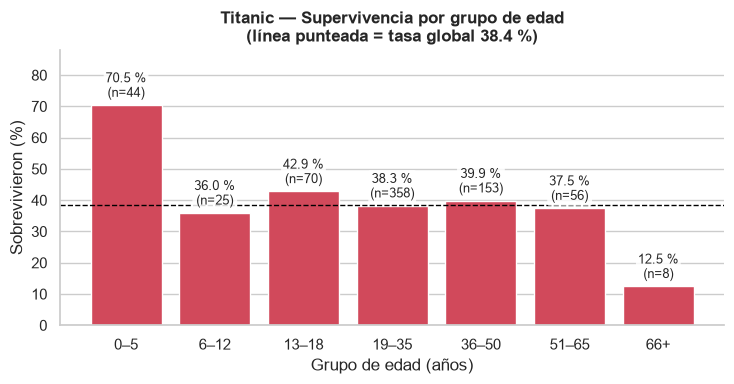

,tasa_%,n
Age,,
0–5,70.455,44
6–12,36.000,25
13–18,42.857,70
19–35,38.268,358
36–50,39.869,153
51–65,37.500,56
66+,12.500,8


In [13]:
grupos_edad = pd.cut(titanic["Age"], bins=[0, 5, 12, 18, 35, 50, 65, 81],
                     labels=["0–5", "6–12", "13–18", "19–35", "36–50", "51–65", "66+"], include_lowest=True)
t_edad = tasa_por_grupo(grupos_edad, titanic["Survived"], "Titanic — Supervivencia por grupo de edad",
                        "Grupo de edad (años)", "Sobrevivieron (%)", "titanic_supervivencia_edad",
                        global_pct=100 * titanic["Survived"].mean(), color=ROJO, figsize=(7.5, 4))
display(t_edad)

**Interpretación.** No es una recta: los menores de 5 años sobreviven 70.5 % (31 de 44), mientras que los demás grupos
hasta 65 años quedan entre ~36 % y 43 %; el grupo 66+ tiene solo 8 pasajeros, muy poca muestra. Esa forma no monótona
explica por qué la correlación lineal con la edad es casi nula (−0.08).

**Pregunta 3.** ¿El efecto de la clase es el mismo para hombres y mujeres?

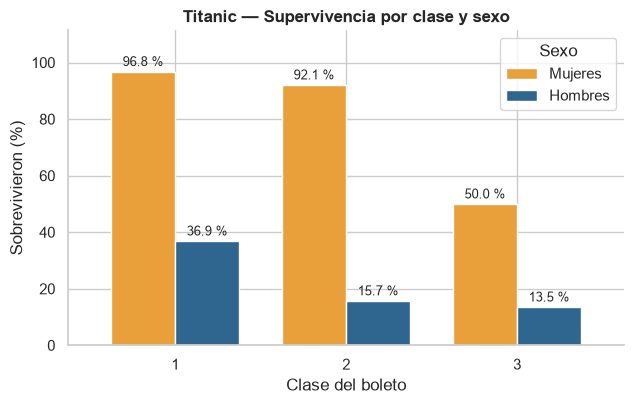

Sex,female,male
Pclass,,
1,96.800,36.900
2,92.100,15.700
3,50.000,13.500


In [14]:
tabla_cs = 100 * titanic.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
tabla_cs[["female", "male"]].plot(kind="bar", ax=ax, color=[NARANJA, AZUL], width=0.75, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f %%", fontsize=9, padding=2)
ax.set_title("Titanic — Supervivencia por clase y sexo")
ax.set_xlabel("Clase del boleto"); ax.set_ylabel("Sobrevivieron (%)")
ax.legend(title="Sexo", labels=["Mujeres", "Hombres"]); ax.margins(y=0.15)
guardar(fig, "titanic_supervivencia_clase_sexo")
display(tabla_cs.round(1))

**Interpretación.** No: sobrevive 96.8 % y 92.1 % de las mujeres de 1.ª y 2.ª clase, pero solo 50 % en 3.ª; entre los
hombres, 36.9 % en 1.ª y 13.5 % en 3.ª. El efecto de la clase depende del sexo (una interacción), algo que una regresión
logística sin términos de interacción no captura.

---
# 2. Credit Card Fraud

> Requiere `data/raw/creditcard.csv` (≈ 144 MB, no está en GitHub): ver el README para descargarlo de Kaggle.
> Las cifras de calidad que se citan ("cifras de B") vienen de `docs/ficha_tecnica.md` y `resultados/`.

In [15]:
fraud = cargar_datos("fraud")
fraud["Estado"] = fraud["Class"].map({0: "Legítima", 1: "Fraude"})                # solo para etiquetas
PAL_F = {"Legítima": GRIS, "Fraude": ROJO}
horas = fraud["Time"] / 3600                      # horas desde la primera transacción del archivo
hora_int = horas.astype(int)
PCT_FRAUDE = 100 * fraud["Class"].mean()
print(f"Fraud: {fraud.shape[0]:,} filas × {fraud.shape[1]} columnas (con la columna auxiliar 'Estado')")
print(f"Fraudes: {int(fraud['Class'].sum()):,} ({PCT_FRAUDE:.3f} %)")
display(fraud.head())

Fraud: 284,807 filas × 32 columnas (con la columna auxiliar 'Estado')
Fraudes: 492 (0.173 %)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Estado
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,...,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0,Legítima
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,...,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0,Legítima
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,...,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0,Legítima
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,...,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0,Legítima
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,...,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0,Legítima


### 2.1 Histogramas

**Pregunta 1.** ¿Cómo se distribuyen los montos de las transacciones y hay montos extremos?

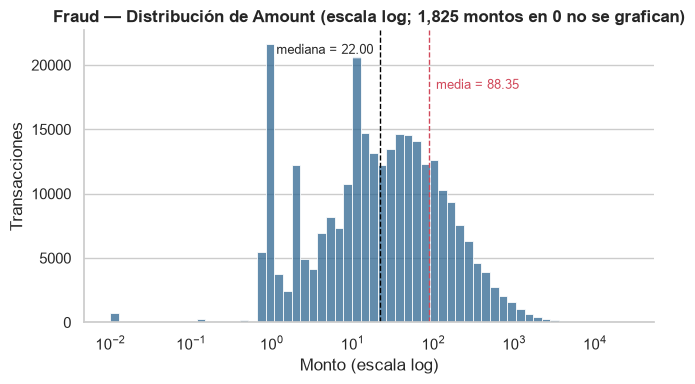

asimetría = 16.98 · p99 = 1,017.97 · máximo = 25,691.16


In [16]:
monto = fraud["Amount"]
positivos = monto[monto > 0]
fig, ax = plt.subplots(figsize=(6.8, 4))
sns.histplot(positivos, bins=60, log_scale=True, color=AZUL, ax=ax)
ax.axvline(monto.median(), ls="--", color="black", lw=1)
ax.axvline(monto.mean(), ls="--", color=ROJO, lw=1)
ax.annotate(f"mediana = {monto.median():.2f}", (monto.median(), ax.get_ylim()[1] * 0.92),
            xytext=(-5, 0), textcoords="offset points", ha="right", fontsize=9, bbox=CAJA)
ax.annotate(f"media = {monto.mean():.2f}", (monto.mean(), ax.get_ylim()[1] * 0.80),
            xytext=(5, 0), textcoords="offset points", fontsize=9, color=ROJO, bbox=CAJA)
ax.set_title(f"Fraud — Distribución de Amount (escala log; {int((monto == 0).sum()):,} montos en 0 no se grafican)")
ax.set_xlabel("Monto (escala log)"); ax.set_ylabel("Transacciones")
guardar(fig, "fraud_hist_monto")
print(f"asimetría = {monto.skew():.2f} · p99 = {monto.quantile(.99):,.2f} · máximo = {monto.max():,.2f}")

**Interpretación.** Asimetría extrema a la derecha (≈ 17): la mediana es 22.00 pero la media sube a 88.35, el p99 llega a
1,017.97 y el máximo a 25,691.16. En escala logarítmica se ve el cuerpo de la distribución: la gran mayoría de los montos
son pequeños y los grandes son raros. Hay 1,825 montos exactamente en 0, que son válidos (cifras de B).

**Pregunta 2.** ¿Cómo se reparten las transacciones a lo largo de las 48 horas que cubre el archivo?

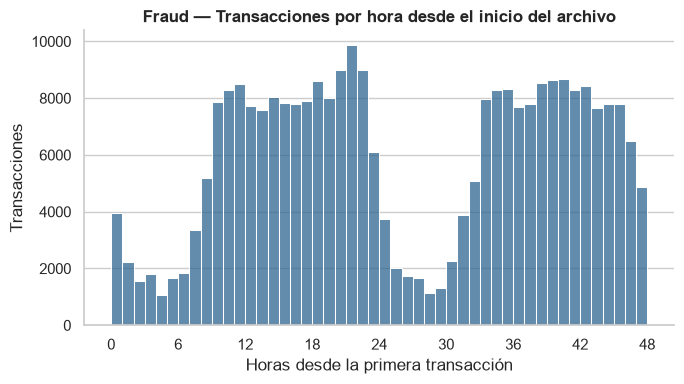

Hora más activa: 21 (9,895 transacciones) · hora menos activa: 4 (1,082 transacciones)


In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(horas, bins=48, color=AZUL, ax=ax)
ax.set_xticks(range(0, 49, 6))
ax.set_title("Fraud — Transacciones por hora desde el inicio del archivo")
ax.set_xlabel("Horas desde la primera transacción"); ax.set_ylabel("Transacciones")
guardar(fig, "fraud_hist_tiempo")
por_hora = hora_int.value_counts().sort_index()
print(f"Hora más activa: {por_hora.idxmax()} ({por_hora.max():,} transacciones) · "
      f"hora menos activa: {por_hora.idxmin()} ({por_hora.min():,} transacciones)")

**Interpretación.** El archivo cubre 48 horas (0 – 172,792 s) y el volumen no es uniforme: sube y baja siguiendo el ritmo
de actividad de los clientes (ver las horas más y menos activas impresas arriba). `Time` es relativo al inicio del
archivo, así que no existiría tal cual en producción (riesgo de fuga temporal señalado por B).

### 2.2 Boxplots

**Pregunta 1.** ¿Los fraudes tienen montos distintos a los de las transacciones legítimas?

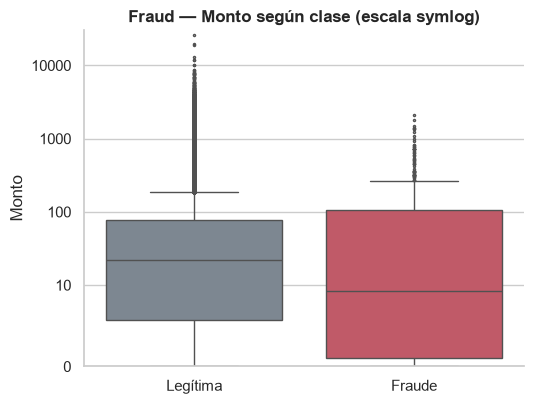

,count,25%,50%,75%,mean,max
Estado,,,,,,
Fraude,492.000,1.000,9.250,105.890,122.211,2125.870
Legítima,284315.000,5.650,22.000,77.050,88.291,25691.160


In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.boxplot(data=fraud, x="Estado", y="Amount", hue="Estado", palette=PAL_F, order=list(PAL_F),
            legend=False, fliersize=1.5, ax=ax)
ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(0, 30000); ax.set_yticks([0, 10, 100, 1000, 10000]); ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_title("Fraud — Monto según clase (escala symlog)")
ax.set_xlabel(""); ax.set_ylabel("Monto")
guardar(fig, "fraud_box_monto_clase")
display(fraud.groupby("Estado")["Amount"].describe()[["count", "25%", "50%", "75%", "mean", "max"]])

**Interpretación.** El monto separa poco las clases: las cajas se traslapan y solo el 18.5 % de los fraudes son outliers
IQR en `Amount` contra el 11.2 % de las legítimas (la tasa de fraude es 0.29 % entre esos outliers vs 0.16 % en el resto;
cifras de B). El monto por sí solo no delata el fraude.

**Pregunta 2.** ¿`V14` se comporta distinto en los fraudes?

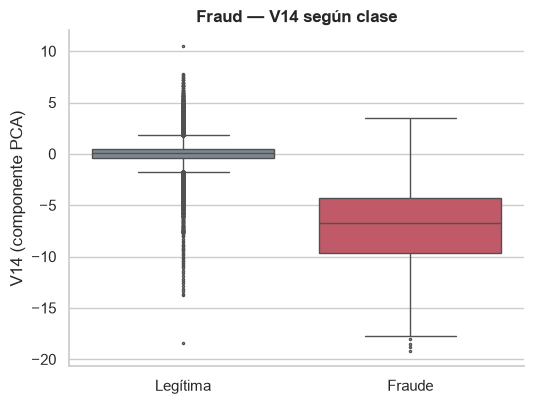

,count,25%,50%,75%,min,max
Estado,,,,,,
Fraude,492.000,-9.693,-6.730,-4.283,-19.214,3.442
Legítima,284315.000,-0.422,0.052,0.494,-18.392,10.527


In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.boxplot(data=fraud, x="Estado", y="V14", hue="Estado", palette=PAL_F, order=list(PAL_F),
            legend=False, fliersize=1.5, ax=ax)
ax.set_title("Fraud — V14 según clase")
ax.set_xlabel(""); ax.set_ylabel("V14 (componente PCA)")
guardar(fig, "fraud_box_v14_clase")
display(fraud.groupby("Estado")["V14"].describe()[["count", "25%", "50%", "75%", "min", "max"]])

**Interpretación.** Mucho: la distribución de `V14` en los fraudes está desplazada y cae en la zona de outliers de las
legítimas. El 87.4 % de los fraudes son outliers IQR en `V14` contra el 4.8 % de las legítimas (cifras de B). Aquí los
outliers **son la señal**, no ruido: recortarlos (winsorizar) borraría justo la información que detecta el fraude.

### 2.3 Barras de variables categóricas (derivadas)

Fraud no tiene categóricas, así que se derivan dos **solo para el EDA** a partir de variables numéricas.

**Pregunta 1.** ¿Cómo se reparte el volumen de transacciones en bloques de 6 horas?

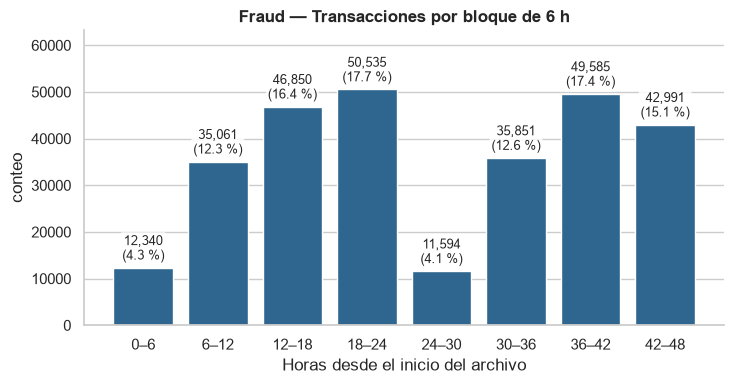

Time
0–6      12340
6–12     35061
12–18    46850
18–24    50535
24–30    11594
30–36    35851
36–42    49585
42–48    42991
Name: count, dtype: int64

In [20]:
etq_bloque = ["0–6", "6–12", "12–18", "18–24", "24–30", "30–36", "36–42", "42–48"]
bloque = pd.cut(horas, bins=range(0, 54, 6), right=False, labels=etq_bloque)
conteo_bloque = barras_conteo(bloque.astype(str), "Fraud — Transacciones por bloque de 6 h",
                              "Horas desde el inicio del archivo", "fraud_barras_bloque",
                              orden=etq_bloque, figsize=(7.5, 4))
display(conteo_bloque)

**Interpretación.** El volumen no se reparte por igual entre los 8 bloques (ver los conteos y porcentajes): la actividad
depende de la hora, por lo que un split aleatorio mezcla momentos de baja y alta actividad. Esta gráfica describe volumen;
la pregunta de riesgo (¿cuándo hay más fraude?) se responde en la sección 2.6.

**Pregunta 2.** ¿Qué tan frecuentes son los montos pequeños frente a los grandes?

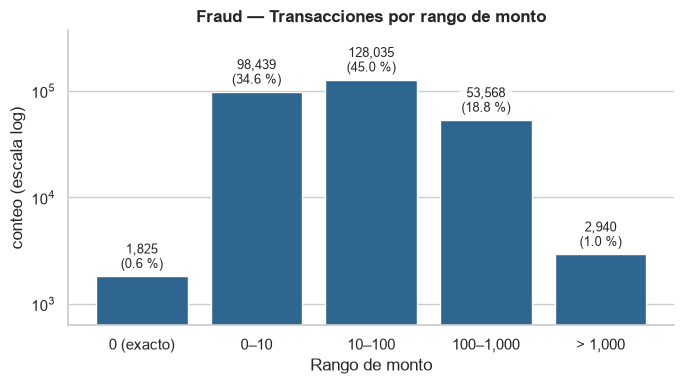

Amount
0 (exacto)      1825
0–10           98439
10–100        128035
100–1,000      53568
> 1,000         2940
Name: count, dtype: int64

In [21]:
etq_monto = ["0 (exacto)", "0–10", "10–100", "100–1,000", "> 1,000"]
banda_monto = pd.cut(fraud["Amount"], bins=[-0.01, 0, 10, 100, 1000, np.inf], labels=etq_monto)
conteo_monto = barras_conteo(banda_monto.astype(str), "Fraud — Transacciones por rango de monto",
                             "Rango de monto", "fraud_barras_monto", orden=etq_monto, log=True, figsize=(7, 4))
display(conteo_monto)

**Interpretación.** Los montos grandes son una minoría: solo 2,940 transacciones (1.03 %) pasan de 1,000 (la barra usa escala logarítmica para que se vean todos los rangos). Los montos en 0 son 1,825 y no son errores (cifras de B).

### 2.4 Matriz de correlación

**Pregunta.** ¿Hay variables redundantes o relacionadas linealmente con el fraude?

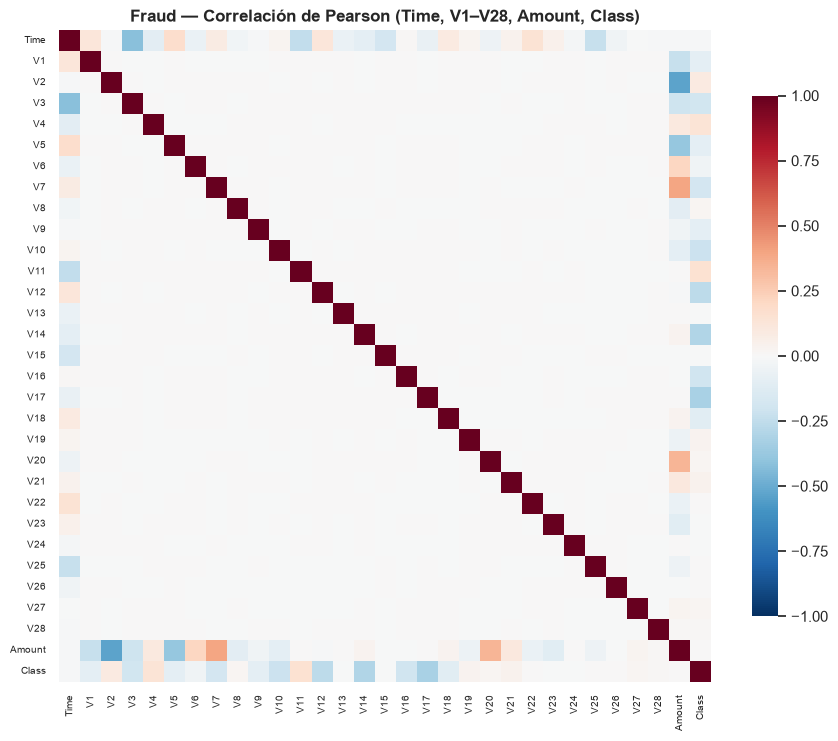

Par más correlacionado: ('Amount', 'V2') |r| = 0.53


In [22]:
corr_f = fraud.drop(columns="Estado").corr()
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr_f, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title("Fraud — Correlación de Pearson (Time, V1–V28, Amount, Class)")
guardar(fig, "fraud_correlacion")
fuera_diag = corr_f.where(~np.eye(len(corr_f), dtype=bool)).abs().stack().sort_values(ascending=False)
print("Par más correlacionado:", fuera_diag.index[0], f"|r| = {fuera_diag.iloc[0]:.2f}")

**Interpretación.** El bloque `V1`–`V28` es casi todo blanco: son componentes PCA y por construcción están
descorrelacionadas entre sí; las relaciones visibles involucran a `Time` y `Amount` con algunas `V`. Ningún par llega a
|r| > 0.8 (el máximo es ≈ 0.53, `V2`–`Amount`; cifras de B), así que no hay redundancia que eliminar. La relación con
`Class` se detalla en la siguiente gráfica.

**Pregunta (complemento).** ¿Cuáles variables se relacionan más con `Class` en términos lineales?

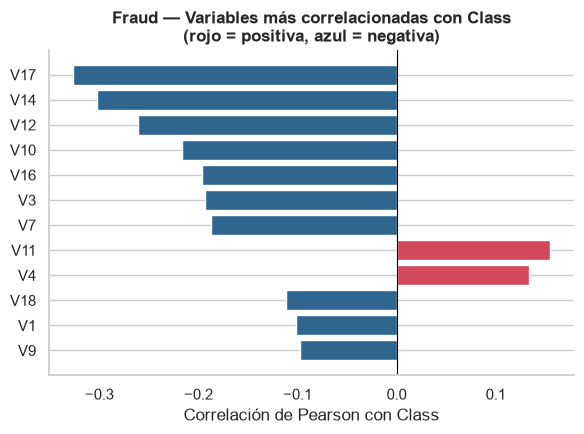

,r con Class
V17,-0.326
V14,-0.303
V12,-0.261
V10,-0.217
V16,-0.197
V3,-0.193
V7,-0.187
V11,0.155
V4,0.133
V18,-0.111


In [23]:
corr_clase = corr_f["Class"].drop("Class")
top = corr_clase.reindex(corr_clase.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=[ROJO if v > 0 else AZUL for v in top.values[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Fraud — Variables más correlacionadas con Class\n(rojo = positiva, azul = negativa)")
ax.set_xlabel("Correlación de Pearson con Class")
guardar(fig, "fraud_correlacion_clase")
display(top.to_frame("r con Class"))

**Interpretación.** Las variables con mayor |r| son `V` (no `Amount` ni `Time`) y su correlación lineal con `Class`
es moderada, alrededor de 0.3 en valor absoluto en el mejor caso (ver los valores). Coinciden con las `V` que más outliers
tienen en los fraudes según B (`V14`, `V12`, `V10`, `V17`), lo que apunta a una señal que no es una recta simple.

### 2.5 Distribución de clases

**Pregunta.** ¿Qué tan raro es el fraude en este dataset?

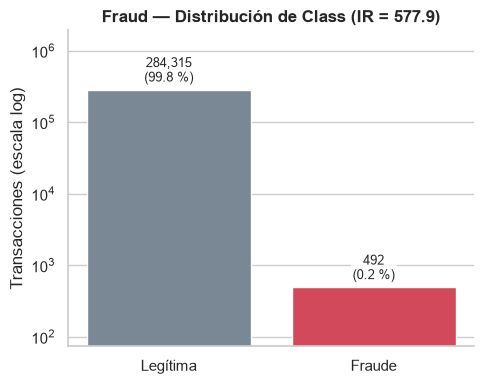

In [24]:
cl_f = fraud["Estado"].value_counts().reindex(list(PAL_F))
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(cl_f.index, cl_f.values, color=[PAL_F[k] for k in cl_f.index])
etiquetar_barras(ax, total=cl_f.sum())
ax.set_yscale("log")
ax.set_title(f"Fraud — Distribución de Class (IR = {cl_f.max() / cl_f.min():.1f})")
ax.set_ylabel("Transacciones (escala log)"); ax.margins(y=0.3)
guardar(fig, "fraud_clases")

**Interpretación.** 284,315 transacciones legítimas (99.827 %) contra 492 fraudes (0.173 %): IR ≈ 578, un desbalance
extremo (en escala lineal la barra de fraudes sería invisible). Por eso el accuracy engaña: decir siempre "no fraude"
acierta 99.83 % y no detecta ningún fraude.

### 2.6 Atributo vs. objetivo

**Pregunta.** ¿El fraude es igual de frecuente a todas las horas?

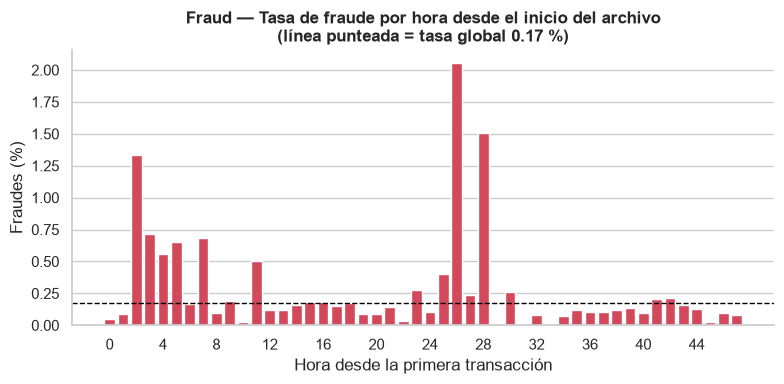

Hora 26: 2.05 % de fraude (n = 1,752)
Hora 28: 1.51 % de fraude (n = 1,127)
Hora 2: 1.33 % de fraude (n = 1,576)


In [25]:
tasa_hora = 100 * fraud.groupby(hora_int)["Class"].mean()
n_hora = fraud.groupby(hora_int).size()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tasa_hora.index, tasa_hora.values, color=ROJO)
ax.axhline(PCT_FRAUDE, ls="--", color="black", lw=1)
ax.set_xticks(range(0, 48, 4))
ax.set_title(f"Fraud — Tasa de fraude por hora desde el inicio del archivo\n(línea punteada = tasa global {PCT_FRAUDE:.2f} %)")
ax.set_xlabel("Hora desde la primera transacción"); ax.set_ylabel("Fraudes (%)")
guardar(fig, "fraud_tasa_por_hora")
top_h = tasa_hora.sort_values(ascending=False).head(3)
for h, t in top_h.items():
    print(f"Hora {h}: {t:.2f} % de fraude (n = {n_hora[h]:,})")

**Interpretación.** No: la tasa de fraude cambia mucho con la hora. Llega a 2.05 % en la hora 26 (n = 1,752), 1.51 % en la 28 y 1.33 % en la 2, contra una tasa global de 0.17 %; los picos caen en las horas de poca actividad (madrugada de cada día), y en la mayoría de las horas de mayor volumen la tasa queda por debajo de 0.2 %. Agrupando por hora del día, las horas 2 y 26 juntas dan 1.71 % (cifra de B). Con pocas transacciones por hora, algunas barras son inestables. Confirma que Time lleva señal y a la vez riesgo de fuga temporal.

### 2.7 Asimetría y relaciones no lineales

**Pregunta 1.** ¿Qué variables son más asimétricas?

In [26]:
cols_f = [c for c in fraud.columns if c not in ("Estado", "Class")]
display(tabla_asimetria(fraud, cols_f, n=10))

,asimetría,curtosis
Amount,16.978,845.093
V28,11.192,933.398
V8,-8.522,220.587
V23,-5.875,440.089
V2,-4.625,95.773
V17,-3.845,94.800
V21,3.593,207.287
V1,-3.281,32.487
V7,2.554,405.607
V5,-2.426,206.905


**Interpretación.** `Amount` (≈ 17) es de las más asimétricas, junto con varias `V` de colas muy pesadas (la curtosis
supera 200 en 8 de las `V` y en `Amount`; cifras de B). Eso hace que media y desviación se distorsionen y justifica
escalar y evaluar la winsorización de `Amount`, pero no la de las `V` (sus colas contienen el fraude).

**Pregunta 2.** ¿El fraude aumenta de forma lineal con el monto?

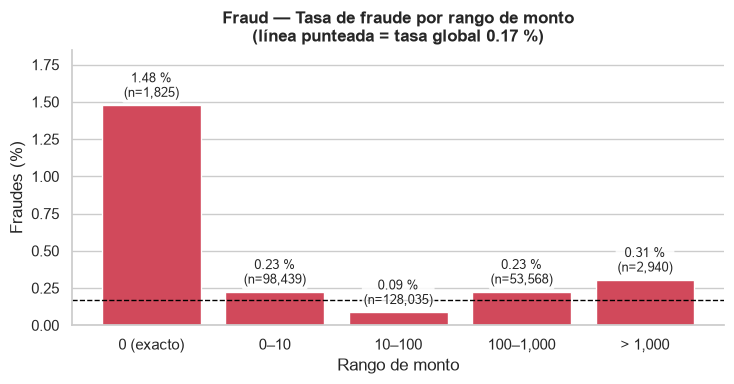

,tasa_%,n
Amount,,
0 (exacto),1.479,1825
0–10,0.226,98439
10–100,0.088,128035
"100–1,000",0.226,53568
"> 1,000",0.306,2940


In [27]:
t_monto = tasa_por_grupo(banda_monto, fraud["Class"], "Fraud — Tasa de fraude por rango de monto",
                         "Rango de monto", "Fraudes (%)", "fraud_tasa_por_monto",
                         global_pct=PCT_FRAUDE, color=ROJO, figsize=(7.5, 4), dec=2)
display(t_monto)

**Interpretación.** Destacan los montos exactamente en 0: tasa de fraude de 1.48 % (27 de 1,825), unas 8.6 veces la
global (0.17 %); es un caso especial más que una tendencia con el monto. Para los demás rangos, lee cada barra frente a la
línea punteada (tasa global). En conjunto el monto es una señal débil: solo el 18.5 % de los fraudes son outliers en
`Amount` (cifras de B).

---
# 3. Resumen para la presentación y para los demás roles

**Hallazgos del EDA (Rol C)**

1. **Titanic: sexo y clase explican la supervivencia, y lo hacen juntos.** 74 % de las mujeres vs 19 % de los hombres;
   en 1.ª y 2.ª clase sobrevive más del 90 % de las mujeres, en 3.ª solo el 50 % (`figuras/c_titanic_supervivencia_clase_sexo.png`).
2. **Titanic: `Fare` es muy asimétrica** (4.79; mediana 14.45 vs media 32.20) y es la candidata a winsorización;
   `Age` es casi simétrica pero le faltan 19.9 % de los datos.
3. **Fraud: el desbalance es extremo** (0.173 % de fraudes, IR ≈ 578) y el accuracy engaña (`figuras/c_fraud_clases.png`).
4. **Fraud: los outliers son la señal.** El 87.4 % de los fraudes son outliers IQR en `V14` (vs 4.8 % de las legítimas):
   winsorizar las `V` borraría la información (`figuras/c_fraud_box_v14_clase.png`).
5. **Fraud: `Amount` está muy sesgado y separa poco las clases;** `Time` sí cambia la tasa de fraude pero es un riesgo
   de fuga temporal.

**Lo que se le pasa a los demás roles**
- **Rol D:** winsorizar `Fare` (Titanic) y `Amount` (Fraud); **no** winsorizar las `V` de Fraud; en Titanic, `Age` y `Embarked` para imputar.
- **Rol E:** el desbalance de Fraud (IR ≈ 578) es el caso donde el accuracy no sirve.
- **Presentación:** para la diapositiva del hallazgo del EDA, usar el punto 1 (Titanic) o el 4 (Fraud); el 4 conecta directo con la diapositiva de winsorización de D.

In [28]:
print("Figuras guardadas por este notebook en figuras/:")
for p in sorted(FIG.glob("c_*.png")):
    print(" -", p.name)

Figuras guardadas por este notebook en figuras/:
 - c_fraud_barras_bloque.png
 - c_fraud_barras_monto.png
 - c_fraud_box_monto_clase.png
 - c_fraud_box_v14_clase.png
 - c_fraud_clases.png
 - c_fraud_correlacion.png
 - c_fraud_correlacion_clase.png
 - c_fraud_hist_monto.png
 - c_fraud_hist_tiempo.png
 - c_fraud_tasa_por_hora.png
 - c_fraud_tasa_por_monto.png
 - c_titanic_barras_embarque.png
 - c_titanic_barras_sexo.png
 - c_titanic_box_edad_supervivencia.png
 - c_titanic_box_tarifa_clase.png
 - c_titanic_clases.png
 - c_titanic_correlacion.png
 - c_titanic_hist_edad.png
 - c_titanic_hist_tarifa.png
 - c_titanic_supervivencia_clase_sexo.png
 - c_titanic_supervivencia_edad.png
 - c_titanic_supervivencia_sexo.png
